# 02 — Implementación y comparación de modelos

Grupo 4 · Leishmaniosis cutánea en Cajamarca

Este notebook usa el código de `src/`:

- `src/models.py`: los cinco modelos (lineal, árbol de decisión, Random Forest, MLP y CNN temporal).
- `src/evaluation.py`: etiquetas de alerta, umbral y métricas.
- `src/experimento_clima.py`: entrenamiento con partición temporal y selección por validación.
- `src/resultados_finales.py`: tabla comparativa, gráficos y resumen.

Protocolo: ajuste 2001–2015, validación 2016–2018, prueba 2019–2024 (57 distritos).
Dos tareas: **casos** (regresión) y **alerta** de brote (clasificación).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

import experimento_clima as ex
import resultados_finales as rf
from models import MODELS, make_model

## 1. Modelos implementados

Cada modelo tiene dos configuraciones candidatas; abajo, la configuración 0 de cada uno para ambas tareas.

In [2]:
for family in MODELS:
    for task in ("casos", "alerta"):
        print(f"{family:>13} | {task:<6} | {make_model(family, task, 0, climate=False)}")

       lineal | casos  | Pipeline(steps=[('standardscaler', StandardScaler()), ('ridge', Ridge())])
       lineal | alerta | Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(C=0.1, class_weight='balanced',
                                    max_iter=1000))])
        arbol | casos  | DecisionTreeRegressor(max_depth=3, min_samples_leaf=20, random_state=42)
        arbol | alerta | DecisionTreeClassifier(class_weight='balanced', max_depth=3,
                       min_samples_leaf=20, random_state=42)
random_forest | casos  | RandomForestRegressor(max_depth=8, min_samples_leaf=5, n_jobs=2,
                      random_state=42)
random_forest | alerta | RandomForestClassifier(class_weight='balanced', max_depth=8, min_samples_leaf=5,
                       n_jobs=2, random_state=42)
          mlp | casos  | Pipeline(steps=[('standardscaler', StandardScaler()),
                ('mlpregressor',
                 M

## 2. Entrenamiento

Con `RUN_EXPERIMENT = True` se reentrenan los cinco modelos en las dos tareas y las cuatro variantes de datos (1–3 minutos en CPU).
Con `False` se usan los resultados ya guardados en `results/experimento_clima/`, generados con el mismo código
(`python src/ejecutar.py --modo experimento-v1 --reutilizar-datos`).

In [3]:
RUN_EXPERIMENT = False

if RUN_EXPERIMENT:
    import warnings
    from sklearn.exceptions import ConvergenceWarning
    warnings.filterwarnings("ignore", category=ConvergenceWarning)
    datasets = {(p, v): pd.read_csv(ex.DATA / p / f"{v}.csv", dtype={"ubigeo": str},
                                    parse_dates=["fecha_mes"], low_memory=False)
                for p in ex.PROTOCOLS for v in ex.VARIANTS}
    ex.run_experiments(datasets)

pd.read_csv(ROOT / "results/experimento_clima/seleccion_por_validacion.csv")[
    ["protocol", "task", "variant", "family", "validation_score", "RMSE", "PR_AUC"]]

,protocol,task,variant,family,validation_score,RMSE,PR_AUC
0,historico,alerta,solo_casos,random_forest,0.159479,NaN,0.020051
1,historico,casos,solo_casos,random_forest,1.329375,1.015905,NaN
2,oficial,alerta,huecos_cortos,random_forest,0.101793,NaN,0.120300
3,oficial,casos,huecos_cortos,random_forest,1.127049,0.925941,NaN


## 3. Tabla comparativa (`results/metrics.csv`)

In [4]:
rf.main()  # regenera metrics.csv, plots/ y model_comparison.txt
metrics = pd.read_csv(ROOT / "results/metrics.csv")
metrics[["modelo", "entradas", "RMSE", "MAE", "PR_AUC", "F1", "recall", "precision",
         "alertas_detectadas", "falsas_alarmas"]].round(3)

# Tabla comparativa de modelos — protocolo oficial

Prueba 2019–2024, 57 distritos de Cajamarca, 4 104 filas distrito × mes. Ajuste 2001–2015 y validación 2016–2018. ↓ menor es mejor; ↑ mayor es mejor.

| Modelo | Entradas | RMSE ↓ | MAE ↓ | MASE ↓ | PR-AUC ↑ | F1 ↑ | Recall ↑ | Precisión ↑ | Alertas detectadas | Falsas alarmas |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Lineal (Ridge / Logística) | Solo casos | 0,940 | 0,583 | 0,567 | 0,107 | 0,154 | 39 % | 10 % | 47/120 | 443 |
| Lineal (Ridge / Logística) | Casos + clima | 0,940 | 0,584 | 0,568 | 0,112 | 0,071 | 62 % | 4 % | 74/120 | 1890 |
| Árbol de decisión | Solo casos | 0,941 | 0,611 | 0,594 | 0,093 | 0,158 | 36 % | 10 % | 43/120 | 380 |
| Árbol de decisión | Casos + clima | 0,944 | 0,613 | 0,596 | 0,135 | 0,194 | 34 % | 14 % | 41/120 | 261 |
| Random Forest | Solo casos | 0,926 | 0,598 | 0,581 | 0,120 | 0,140 | 55 % | 8 % | 66/120 | 759 |
| Random Forest | Casos + clima | 0,923 | 0,596 | 0,580 | 0,154 | 0,154 | 

,modelo,entradas,RMSE,MAE,PR_AUC,F1,recall,precision,alertas_detectadas,falsas_alarmas
0,Lineal (Ridge / Logística),Solo casos,0.940,0.583,0.107,0.154,0.392,0.096,47/120,443.0
1,Lineal (Ridge / Logística),Casos + clima,0.940,0.584,0.112,0.071,0.617,0.038,74/120,1890.0
2,Árbol de decisión,Solo casos,0.941,0.611,0.093,0.158,0.358,0.102,43/120,380.0
3,Árbol de decisión,Casos + clima,0.944,0.613,0.135,0.194,0.342,0.136,41/120,261.0
4,Random Forest,Solo casos,0.926,0.598,0.120,0.140,0.550,0.080,66/120,759.0
5,Random Forest,Casos + clima,0.923,0.596,0.154,0.154,0.592,0.088,71/120,734.0
6,Red neuronal MLP,Solo casos,0.922,0.575,0.121,0.147,0.542,0.085,65/120,699.0
7,Red neuronal MLP,Casos + clima,0.919,0.573,0.132,0.132,0.492,0.076,59/120,713.0
8,Red convolucional CNN,Solo casos,0.938,0.621,0.112,0.142,0.417,0.086,50/120,532.0
9,Red convolucional CNN,Casos + clima,0.941,0.632,0.104,0.159,0.192,0.136,23/120,146.0


## 4. Gráficos (`results/plots/`)

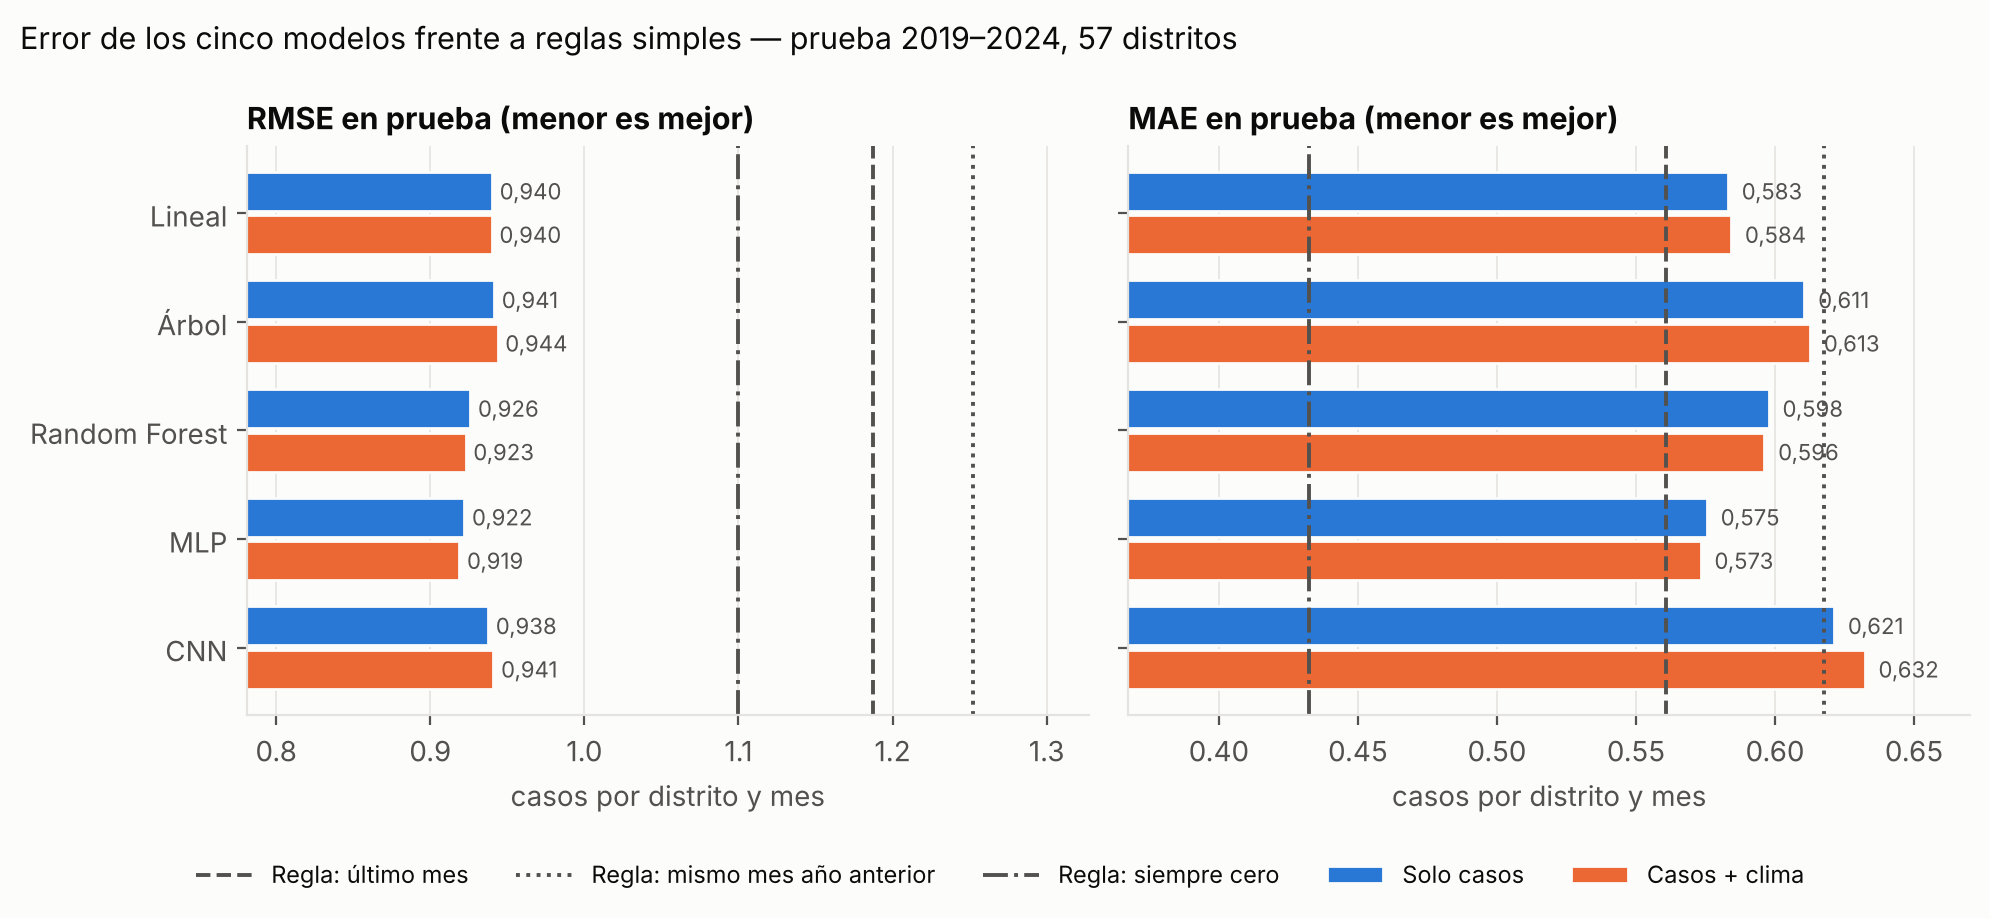

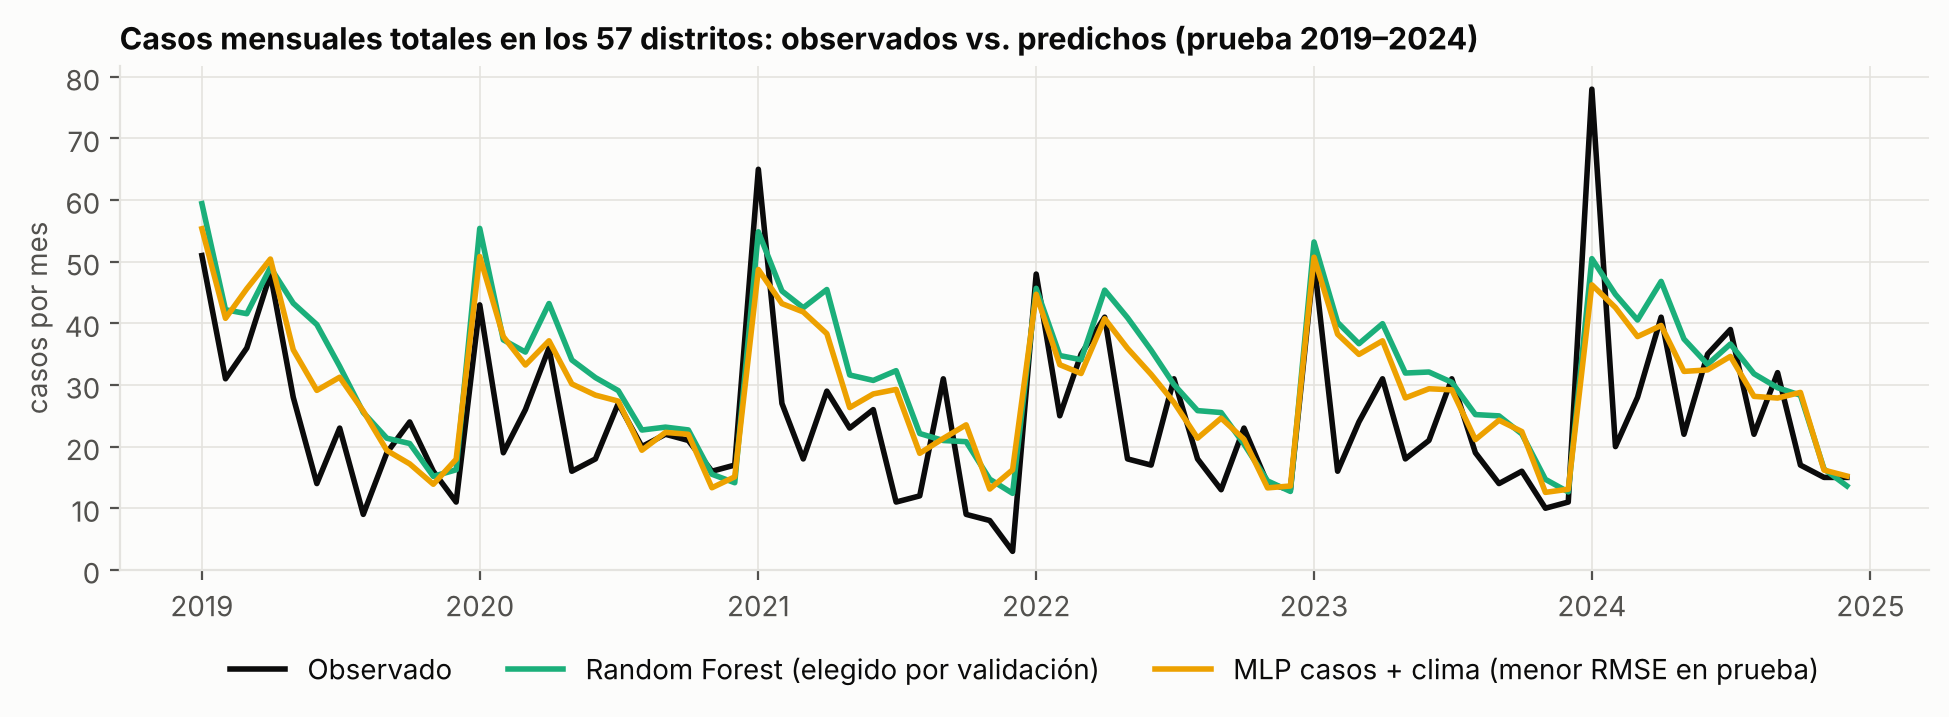

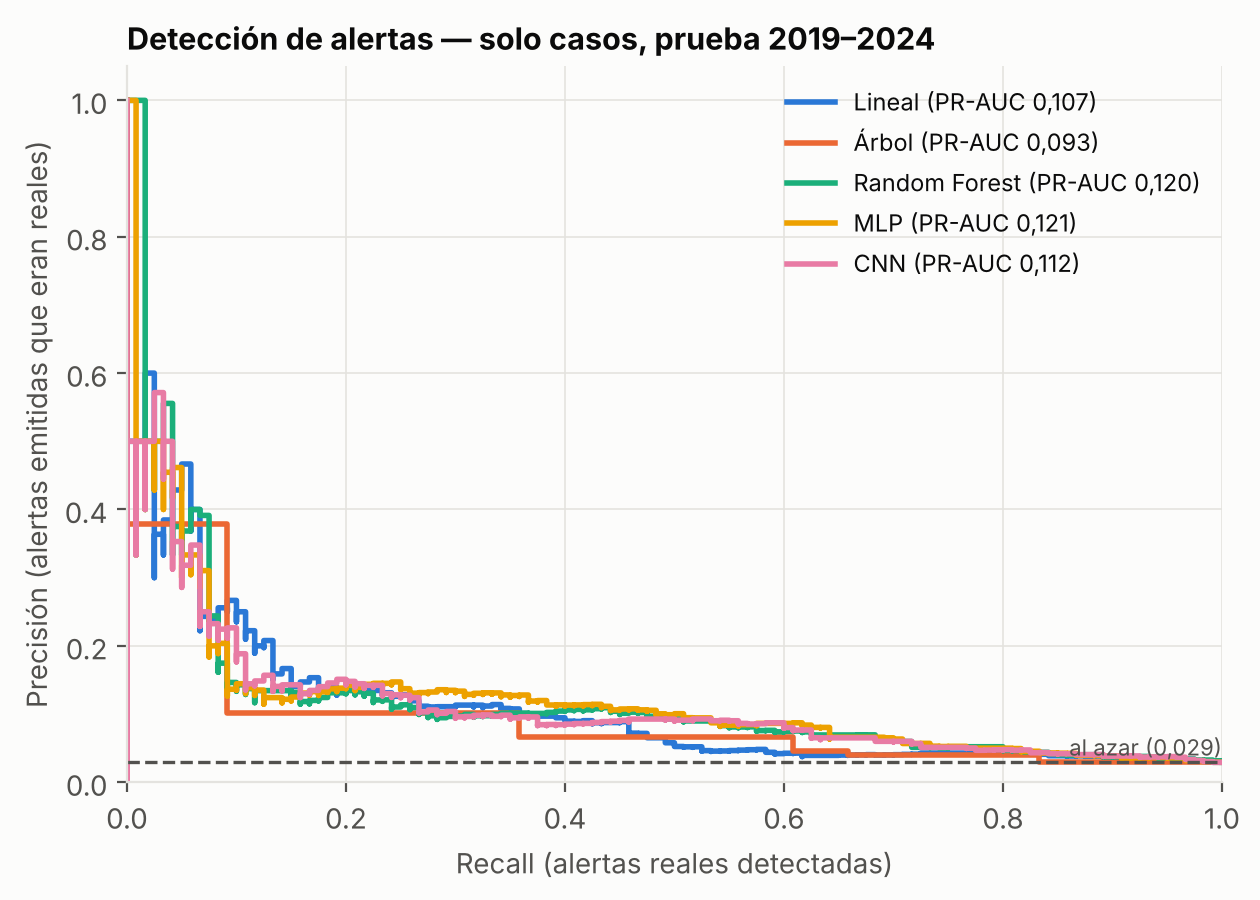

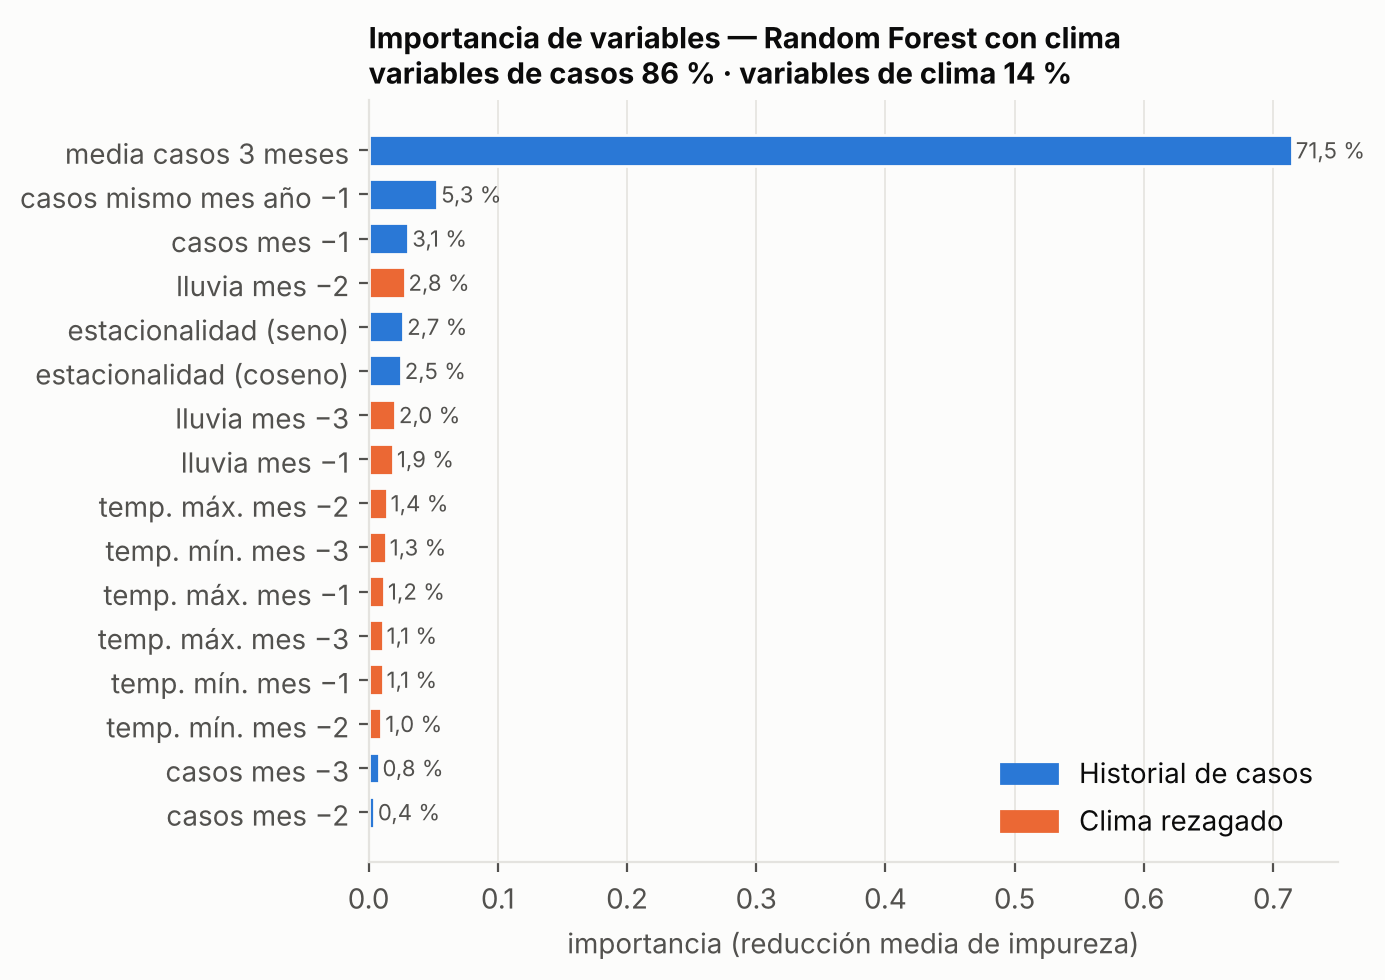

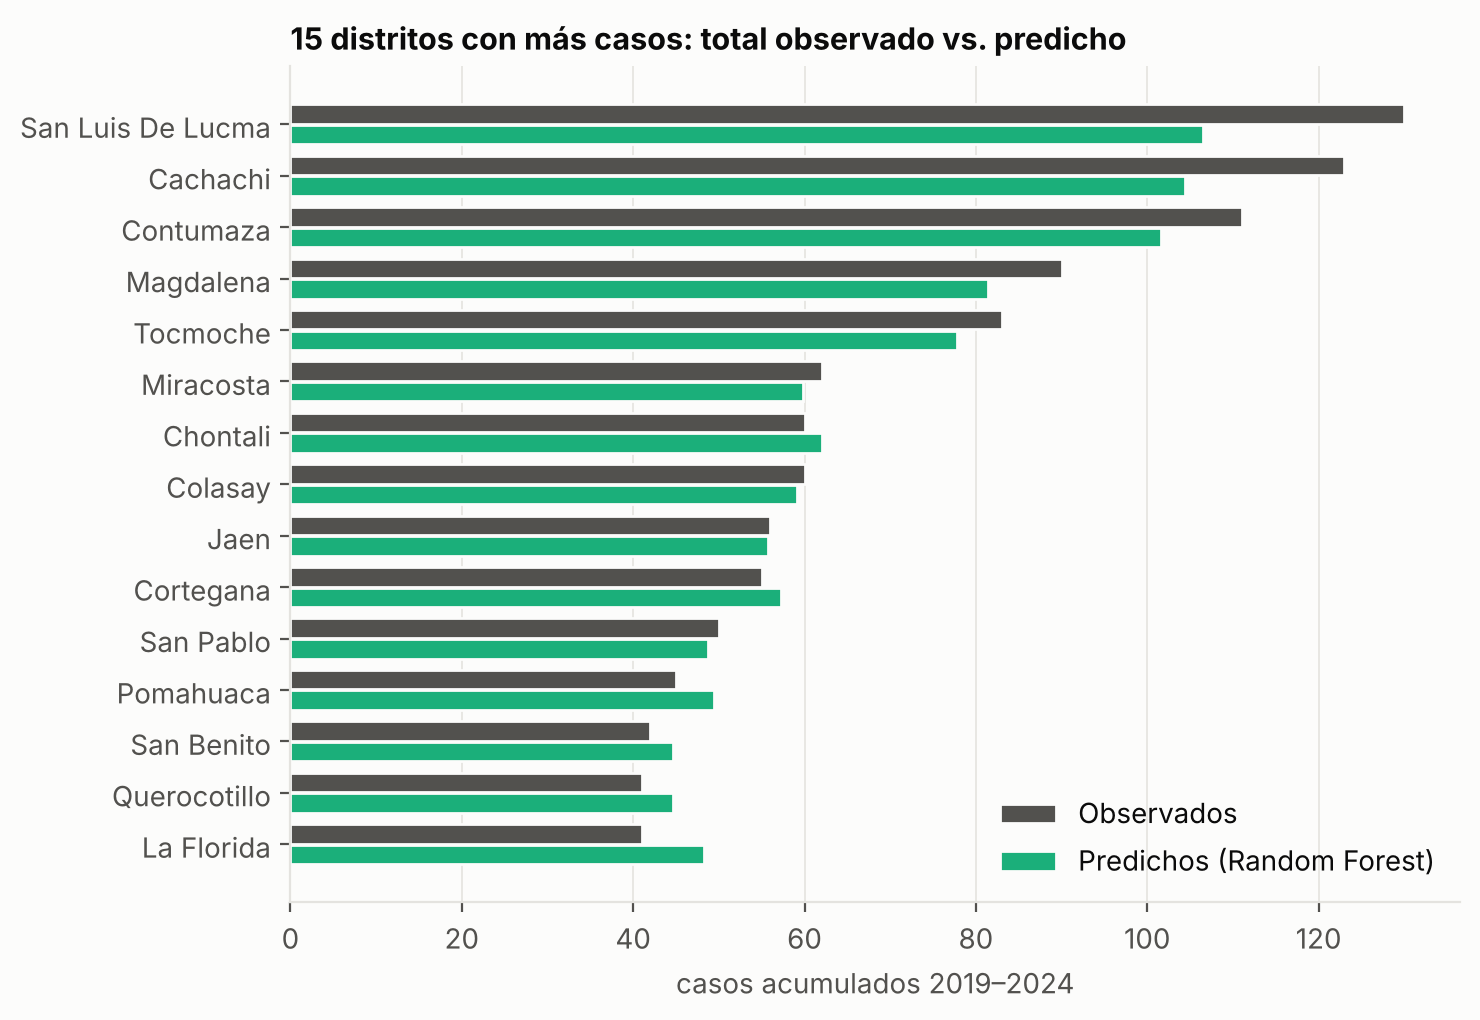

In [5]:
for name in ["fig1_error_por_modelo", "fig2_observado_vs_predicho", "fig3_curvas_precision_recall",
             "fig4_importancia_variables_rf", "fig5_casos_por_distrito"]:
    display(Image(filename=str(ROOT / "results/plots" / f"{name}.png"), width=800))

## 5. Resumen y análisis (`results/model_comparison.txt`)

In [6]:
print((ROOT / "results/model_comparison.txt").read_text(encoding="utf-8"))

RESUMEN DE RESULTADOS Y ANÁLISIS — Grupo 4, leishmaniosis cutánea en Cajamarca

Protocolo: ajuste 2001-2015, validación 2016-2018, prueba 2019-2024.
Prueba: 4104 filas distrito x mes de 57 distritos. Semilla 42.
Tareas: casos (regresión, mes siguiente) y alerta (clasificación de brote).

1. TABLA COMPARATIVA (prueba)
------------------------------------------------------------------------------
Modelo / entradas                         RMSE     MAE   PR-AUC    Alertas
Lineal / Solo casos                      0.940   0.583    0.107     47/120
Lineal / Casos + clima                   0.940   0.584    0.112     74/120
Árbol / Solo casos                       0.941   0.611    0.093     43/120
Árbol / Casos + clima                    0.944   0.613    0.135     41/120
Random Forest / Solo casos               0.926   0.598    0.120     66/120
Random Forest / Casos + clima            0.923   0.596    0.154     71/120
MLP / Solo casos                         0.922   0.575    0.121     65/120
ML

## Conclusiones

- **Random Forest** (elegido por validación) y **MLP** son los mejores y están empatados en la práctica.
- Los modelos reducen el RMSE ~16 % frente a predecir siempre cero y detectan alertas ~4 veces mejor que el azar.
- En MAE ganan las reglas simples, porque el 75 % de los meses-distrito tiene cero casos.
- El clima no aporta mejoras consistentes, pero los datos de SENAMHI terminan en 2015: no se puede descartar su efecto.

Análisis completo en `docs/ANALISIS_RESULTADOS.md` y en `report.pdf`.